# Evaluación 3: Clasificación

* Javiera Cuevas
* Antonia Peña
* Arline Mitchell
* Nicolás Morales

**Fecha de Creación:** Noviembre de 2026  
**Versión:** 1.0  

---

## Descripción
Una institución financiera recibe solicitudes de préstamos hipotecarios y necesita anticipar el incumplimiento o impago (`Riesgo_Impago`: 1 = impago, 0 = cumple). Este notebook desarrolla:

* **Fase 1:** carga del dataset `riesgo_crediticio.csv` y diagnóstico de calidad (nulos, tipos, duplicados, inconsistencias lógicas, outliers y desbalance del target).
* **Fase 2:** diseño de un `Pipeline` de Scikit-Learn con `ColumnTransformer` que automatiza la limpieza y el escalado sin fuga de datos (*data leakage*).
* **Fase 3:** división Train/Test estratificada (75/25), modelo base (`DecisionTreeClassifier` con parámetros por defecto) y modelo optimizado con `RandomizedSearchCV` sobre 6 hiperparámetros, validado con `StratifiedKFold` (5 folds) y la métrica F2 de la clase impago.
* **Fase 4:** evaluación de ambos modelos sobre el conjunto de prueba con dos métricas (Recall y Precision), interpretación de las matrices de confusión y traducción de los errores (Falsos Negativos y Falsos Positivos) al impacto financiero de la institución (\$1.500.000 por crédito impago otorgado vs \$200.000 por crédito viable denegado).


> Se usa `random_state = 29` en todo el trabajo para poder comparar resultados.

---

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, FunctionTransformer
from sklearn.model_selection import train_test_split

# Configuración inicial
RANDOM_STATE = 29
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Carga del dataset desde el repositorio de GitHub
!wget -q -O riesgo_crediticio.csv 'https://raw.githubusercontent.com/javcaves/Inteligencia-Artificial/main/E3-Classifier/riesgo_crediticio.csv'
df = pd.read_csv('riesgo_crediticio.csv')
df.head()

,Unnamed: 0,Ingreso_Anual,Monto_Prestamo,Puntaje_Credito,Relacion_Deuda_Ingreso,Riesgo_Impago
0,0,"39,785.55","85,246.38",694.00,70.00,0
1,1,"69,773.95","244,260.00",622.00,10.65,0
2,2,"127,770.68","209,310.35",780.00,42.70,0
3,3,"16,799.80","213,059.98",741.00,48.04,0
4,4,"70,229.83","219,523.13",714.00,25.58,0


# Fase 1: Diagnóstico y Calidad de Datos (EDA)
### 1.1 Caracterización del dataset

In [ ]:
print(f"Cantidad de registros: {df.shape[0]:,}")
print(f"Cantidad de columnas: {df.shape[1]}\n")

print("--- Tipos de datos y nulos ---")
df.info()

print("\n--- Primeras filas ---")
display(df.head())

Cantidad de registros: 25,000
Cantidad de columnas: 6

--- Tipos de datos y nulos ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              25000 non-null  int64  
 1   Ingreso_Anual           25000 non-null  float64
 2   Monto_Prestamo          25000 non-null  float64
 3   Puntaje_Credito         25000 non-null  float64
 4   Relacion_Deuda_Ingreso  25000 non-null  float64
 5   Riesgo_Impago           25000 non-null  int64  
dtypes: float64(4), int64(2)
memory usage: 1.1 MB

--- Primeras filas ---


,Unnamed: 0,Ingreso_Anual,Monto_Prestamo,Puntaje_Credito,Relacion_Deuda_Ingreso,Riesgo_Impago
0,0,"39,785.55","85,246.38",694.00,70.00,0
1,1,"69,773.95","244,260.00",622.00,10.65,0
2,2,"127,770.68","209,310.35",780.00,42.70,0
3,3,"16,799.80","213,059.98",741.00,48.04,0
4,4,"70,229.83","219,523.13",714.00,25.58,0


In [ ]:
# La columna 'Unnamed: 0' parece un índice exportado por error desde pandas. Se verifica:
es_indice = (df['Unnamed: 0'] == np.arange(len(df))).all()
print(f"¿'Unnamed: 0' es solo el número de fila (0, 1, 2, ...)? -> {es_indice}")

# Se elimina porque no es información de negocio y podría inducir ruido en el modelo
if es_indice:
    df = df.drop(columns='Unnamed: 0')

print("\nColumnas finales:", list(df.columns))

¿'Unnamed: 0' es solo el número de fila (0, 1, 2, ...)? -> True

Columnas finales: ['Ingreso_Anual', 'Monto_Prestamo', 'Puntaje_Credito', 'Relacion_Deuda_Ingreso', 'Riesgo_Impago']


**Análisis 1.1: Caracterización**
* El dataset tiene **25.000 solicitudes** y 6 columnas originales. Todas son numéricas (`float64` e `int64`); **no hay variables categóricas**.
* `Unnamed: 0` es solo un índice de fila exportado por error (coincide exactamente con 0, 1, 2, ...). No aporta información de negocio, por lo que se **elimina** para que el modelo no lo use como predictor.
* **Predictores (4):** `Ingreso_Anual`, `Monto_Prestamo`, `Puntaje_Credito`, `Relacion_Deuda_Ingreso`, todos continuos.
* **Target:** `Riesgo_Impago` (binaria: 0 = paga, 1 = impago).

### 1.2 Valores faltantes

In [ ]:
nulos = df.isnull().sum()
df_nulos = pd.DataFrame({'Cantidad de Nulos': nulos, 'Porcentaje (%)': nulos / len(df) * 100})
display(df_nulos)
print(f"\nTotal de celdas nulas en el dataset: {df.isnull().sum().sum()}")

,Cantidad de Nulos,Porcentaje (%)
Ingreso_Anual,0,0.00
Monto_Prestamo,0,0.00
Puntaje_Credito,0,0.00
Relacion_Deuda_Ingreso,0,0.00
Riesgo_Impago,0,0.00



Total de celdas nulas en el dataset: 0


**Análisis 1.2: Valores faltantes**
* **No hay valores nulos** en ninguna variable (0 %).
* Aun así, el pipeline de la Fase 2 incluirá un `SimpleImputer` (mediana). Así queda preparado para solicitudes futuras con datos faltantes y para los valores inválidos que se conviertan a `NaN` (ver 1.4).

### 1.3 Registros duplicados

In [ ]:
duplicados = df.duplicated().sum()
print(f"Registros duplicados: {duplicados} ({duplicados / len(df) * 100:.2f}%)")

Registros duplicados: 0 (0.00%)


**Análisis 1.3: Duplicados**
* **No hay registros duplicados.** El dataset no tiene un identificador de cliente; aun así, ninguna fila se repite completa, así que no se elimina ni se pondera nada.

### 1.4 Inconsistencias lógicas y rangos válidos

In [ ]:
# Reglas de negocio:
#  - Ingreso, monto del préstamo > 0
#  - Puntaje de crédito en la escala 300-850
#  - Relación deuda/ingreso (DTI %) entre 0 y 100
#  - Target solo puede ser 0 o 1
reglas = {
    'Ingreso_Anual <= 0':                    (df['Ingreso_Anual'] <= 0).sum(),
    'Monto_Prestamo <= 0':                   (df['Monto_Prestamo'] <= 0).sum(),
    'Puntaje_Credito fuera de [300, 850]':   ((df['Puntaje_Credito'] < 300) | (df['Puntaje_Credito'] > 850)).sum(),
    'Relacion_Deuda_Ingreso fuera de [0,100]': ((df['Relacion_Deuda_Ingreso'] < 0) | (df['Relacion_Deuda_Ingreso'] > 100)).sum(),
    'Riesgo_Impago distinto de 0 y 1':       (~df['Riesgo_Impago'].isin([0, 1])).sum(),
}
display(pd.DataFrame.from_dict(reglas, orient='index', columns=['Registros inválidos']))

print("--- Valores en los límites (posibles topes del sistema) ---")
print(f"Monto_Prestamo == mínimo ({df['Monto_Prestamo'].min():,.0f}): {(df['Monto_Prestamo'] == df['Monto_Prestamo'].min()).sum()} registros")
print(f"Puntaje_Credito == 850 (máximo de la escala): {(df['Puntaje_Credito'] == 850).sum()} registros")
print(f"Relacion_Deuda_Ingreso == máximo ({df['Relacion_Deuda_Ingreso'].max():.0f}%): {(df['Relacion_Deuda_Ingreso'] == df['Relacion_Deuda_Ingreso'].max()).sum()} registros")
print(f"Relacion_Deuda_Ingreso == mínimo ({df['Relacion_Deuda_Ingreso'].min():.0f}%): {(df['Relacion_Deuda_Ingreso'] == df['Relacion_Deuda_Ingreso'].min()).sum()} registros")

# Coherencia entre variables: monto solicitado vs ingreso anual
ratio = df['Monto_Prestamo'] / df['Ingreso_Anual']
print(f"\nSolicitudes con préstamo > 10 veces el ingreso anual: {(ratio > 10).sum()} ({(ratio > 10).mean() * 100:.1f}%)")
print(f"Tasa de impago con ratio > 10: {df.loc[ratio > 10, 'Riesgo_Impago'].mean() * 100:.1f}%  |  con ratio <= 10: {df.loc[ratio <= 10, 'Riesgo_Impago'].mean() * 100:.1f}%")

,Registros inválidos
Ingreso_Anual <= 0,0
Monto_Prestamo <= 0,0
"Puntaje_Credito fuera de [300, 850]",0
"Relacion_Deuda_Ingreso fuera de [0,100]",0
Riesgo_Impago distinto de 0 y 1,0


--- Valores en los límites (posibles topes del sistema) ---
Monto_Prestamo == mínimo (50,000): 53 registros
Puntaje_Credito == 850 (máximo de la escala): 49 registros
Relacion_Deuda_Ingreso == máximo (70%): 196 registros
Relacion_Deuda_Ingreso == mínimo (5%): 631 registros

Solicitudes con préstamo > 10 veces el ingreso anual: 1785 (7.1%)
Tasa de impago con ratio > 10: 16.1%  |  con ratio <= 10: 6.5%


**Análisis 1.4: Inconsistencias lógicas**
* **No se detectaron valores inválidos**: no hay ingresos ni montos $\le 0$, el puntaje de crédito está dentro de 300-850, el DTI está entre 0 % y 100 % y el target solo toma valores 0 y 1.
* **Valores en los límites (no son errores):** los montos parten exactamente en \$50.000 (53 registros en ese piso), el DTI va de 5 % a 70 % (196 registros en el tope de 70 %) y 49 clientes tienen el puntaje máximo de 850. Sugiere que el sistema de origen aplica pisos y techos; se conservan porque son valores posibles.
* **Coherencia entre variables:** 1.785 solicitudes (7,1 %) piden un préstamo de más de 10 veces su ingreso anual. Es una señal de riesgo, no un error: su tasa de impago (16,1 %) es mucho mayor que la del resto (6,5 %). Se **conservan**.
* **Estrategia:** aunque hoy no hay datos inválidos, el pipeline incluye un paso que convierte cualquier valor imposible a `NaN` para que lo trate el imputador. Así el mismo flujo sirve para datos nuevos.

### 1.5 Estadísticos descriptivos y valores atípicos (outliers)

,count,mean,std,min,25%,50%,75%,max
Ingreso_Anual,"25,000.00","55,824.44","29,804.90","7,832.12","35,051.32","49,234.68","68,923.52","348,135.55"
Monto_Prestamo,"25,000.00","220,162.89","60,059.30","50,000.00","179,438.08","220,241.47","261,003.36","451,784.21"
Puntaje_Credito,"25,000.00",680.03,59.78,457.00,640.00,680.00,721.00,850.00
Relacion_Deuda_Ingreso,"25,000.00",24.03,13.62,5.00,13.79,21.45,31.38,70.00


,Límite inf.,Límite sup.,Outliers,% outliers,Asimetría (skew)
Variable,,,,,
Ingreso_Anual,"-15,756.99","119,731.82",976,3.90,1.70
Monto_Prestamo,"57,090.15","383,351.29",157,0.63,-0.00
Puntaje_Credito,518.50,842.50,167,0.67,-0.03
Relacion_Deuda_Ingreso,-12.60,57.77,663,2.65,0.99


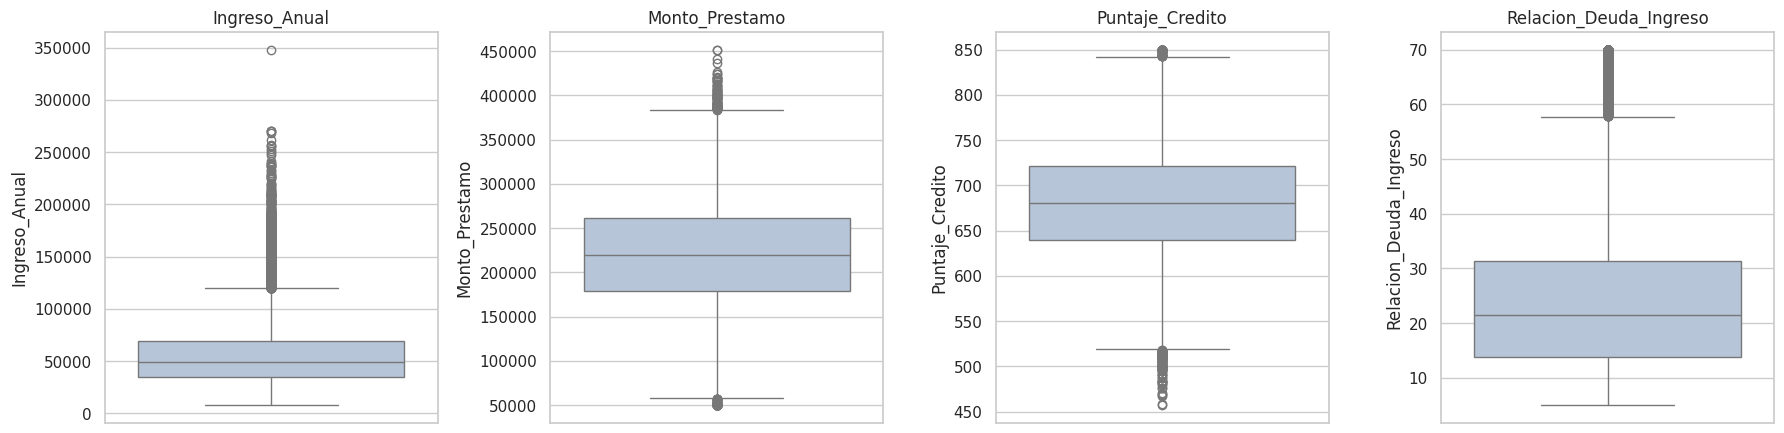

In [ ]:
predictores = ['Ingreso_Anual', 'Monto_Prestamo', 'Puntaje_Credito', 'Relacion_Deuda_Ingreso']

display(df[predictores].describe().T)

# Outliers por regla del rango intercuartílico (IQR)
filas = []
for col in predictores:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    filas.append({'Variable': col, 'Límite inf.': lim_inf, 'Límite sup.': lim_sup,
                  'Outliers': n_out, '% outliers': n_out / len(df) * 100, 'Asimetría (skew)': df[col].skew()})
display(pd.DataFrame(filas).set_index('Variable'))

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, col in zip(axes, predictores):
    sns.boxplot(y=df[col], ax=ax, color='lightsteelblue')
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Análisis 1.5: Valores atípicos**
* **`Ingreso_Anual`** concentra los outliers más importantes: 976 registros (3,9 %) sobre el límite superior, con una cola larga hacia la derecha (asimetría 1,70; máximo \$348.136 frente a una mediana de \$49.235).
* **`Relacion_Deuda_Ingreso`:** 663 registros (2,7 %) con DTI alto, asimetría positiva (0,99).
* **`Puntaje_Credito`** (167) y **`Monto_Prestamo`** (157) tienen pocos outliers y distribuciones prácticamente simétricas.
* **Valor extremo vs. valor inválido:** un ingreso de \$300.000 o un DTI de 70 % son poco frecuentes pero **posibles** (extremos reales). Un ingreso negativo sería **inválido**; no hay ninguno (ver 1.4).
* **Estrategia:** **no se eliminan** los outliers. Son clientes reales y los DTI altos están justamente asociados al impago (ver 1.7); borrarlos le quitaría al modelo los casos de mayor riesgo. En el pipeline se usa `RobustScaler` (basado en mediana e IQR), que no se distorsiona con estos extremos.

### 1.6 Variable objetivo: desbalance de clases

,Clientes,Porcentaje (%)
0 = Paga,23211,92.84
1 = Impago,1789,7.16


Razón de desbalance: 13.0 cumplidores por cada impago


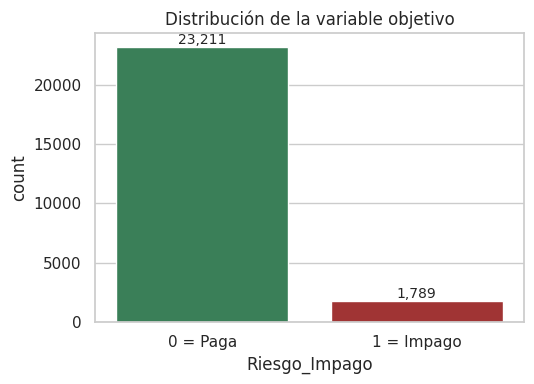


Accuracy de un modelo que aprueba a todos: 92.84%
Pérdida de ese modelo: 1,789 impagos x $1,500,000 = $2,683,500,000
Costo de un impago vs. una oportunidad perdida: 7.5 a 1


In [ ]:
conteo = df['Riesgo_Impago'].value_counts().sort_index()
proporcion = df['Riesgo_Impago'].value_counts(normalize=True).sort_index() * 100
display(pd.DataFrame({'Clientes': conteo, 'Porcentaje (%)': proporcion}, index=[0, 1]).rename(index={0: '0 = Paga', 1: '1 = Impago'}))

print(f"Razón de desbalance: {conteo[0] / conteo[1]:.1f} cumplidores por cada impago")

fig, ax = plt.subplots(figsize=(5.5, 4))
sns.countplot(x='Riesgo_Impago', data=df, hue='Riesgo_Impago', palette=['seagreen', 'firebrick'], legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=10)
ax.set_xticks([0, 1]); ax.set_xticklabels(['0 = Paga', '1 = Impago'])
ax.set_title('Distribución de la variable objetivo')
plt.tight_layout()
plt.show()

# Referencia de negocio: un "modelo" que aprueba a todos
COSTO_FN = 1_500_000   # crédito otorgado que termina en impago
COSTO_FP = 200_000     # crédito viable denegado (interés perdido)
print(f"\nAccuracy de un modelo que aprueba a todos: {conteo[0] / len(df) * 100:.2f}%")
print(f"Pérdida de ese modelo: {conteo[1]:,} impagos x ${COSTO_FN:,} = ${conteo[1] * COSTO_FN:,}")
print(f"Costo de un impago vs. una oportunidad perdida: {COSTO_FN / COSTO_FP:.1f} a 1")

**Análisis 1.6: Desbalance del target**
* Solo **1.789 clientes (7,16 %)** caen en impago; **23.211 (92,84 %)** pagan. Hay ~13 cumplidores por cada impago.
* **Implicancia de negocio:** un "modelo" que apruebe a todos tendría un *accuracy* de 92,84 % sin detectar ni un solo impago, y le costaría a la institución 1.789 × \$1.500.000 = **\$2.683.500.000**. Por eso el *accuracy* no sirve como medida principal y en la Fase 3 la división train/test debe **estratificarse** para conservar el 7,16 % en ambos conjuntos.
* Como equivocarse con un impago cuesta 7,5 veces más que rechazar a un buen cliente (\$1.500.000 vs \$200.000), el modelo debe priorizar la detección de la clase minoritaria (impago).

### 1.7 Relación de los predictores con el riesgo de impago


Riesgo_Impago                   0 = Paga  1 = Impago
Ingreso_Anual          mean    56,757.46   43,719.24
                       median  50,131.74   39,429.90
Monto_Prestamo         mean   218,140.82  246,397.83
                       median 218,518.00  246,809.64
Puntaje_Credito        mean       682.36      649.85
                       median     682.00      650.00
Relacion_Deuda_Ingreso mean        22.86       39.18
                       median      20.68       38.04

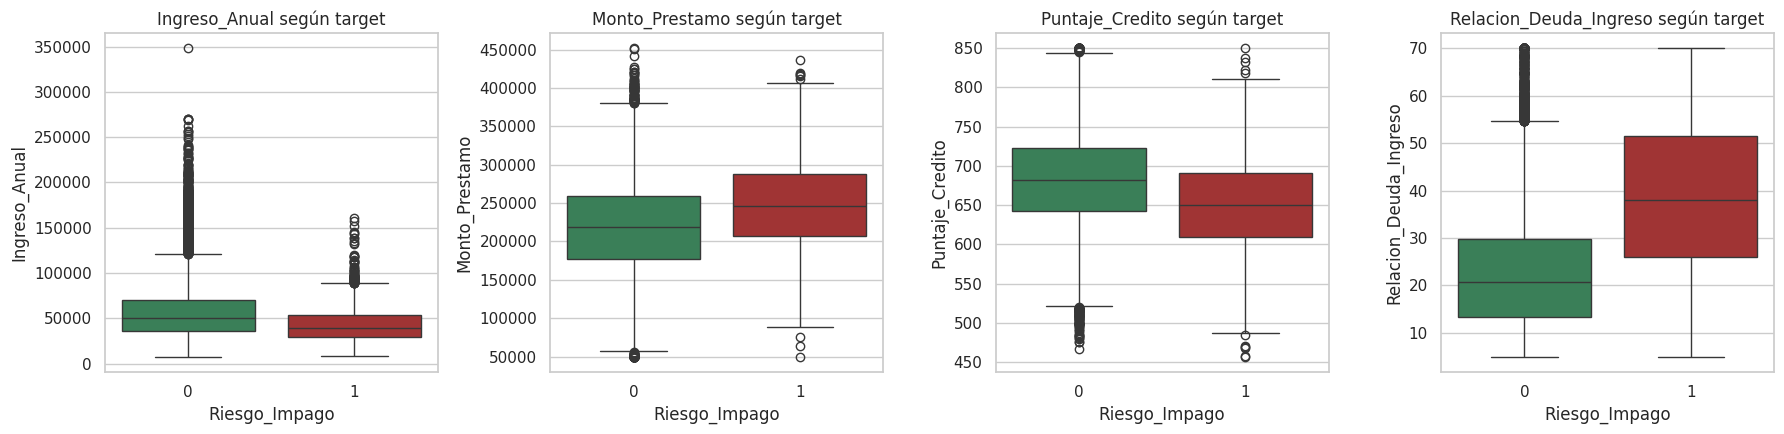

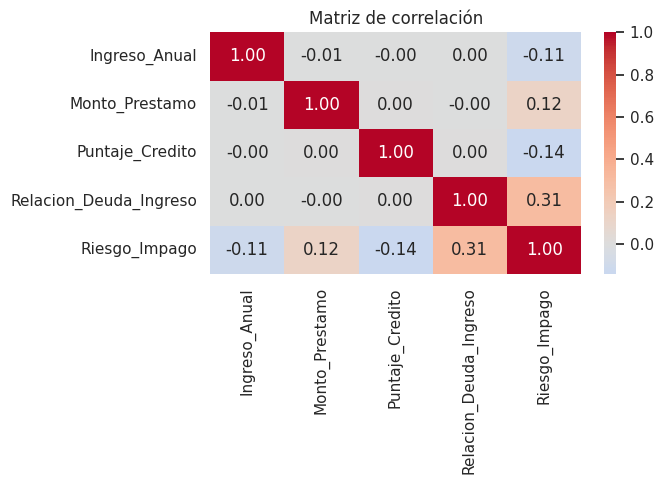

In [ ]:
# Comparación de promedios y medianas por clase
display(df.groupby('Riesgo_Impago')[predictores].agg(['mean', 'median']).rename(index={0: '0 = Paga', 1: '1 = Impago'}).T)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, col in zip(axes, predictores):
    sns.boxplot(x='Riesgo_Impago', y=col, data=df, hue='Riesgo_Impago', palette=['seagreen', 'firebrick'], legend=False, ax=ax)
    ax.set_title(f'{col} según target')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de correlación')
plt.tight_layout()
plt.show()

**Análisis 1.7: Relación con el target**
* **`Relacion_Deuda_Ingreso`** es el predictor más fuerte (correlación 0,31 con el target): los clientes en impago tienen un DTI promedio de 39,2 % frente a 22,9 % de quienes pagan.
* **`Puntaje_Credito`** (-0,14): menor puntaje, mayor riesgo (649,8 vs 682,4 en promedio).
* **`Monto_Prestamo`** (+0,12) e **`Ingreso_Anual`** (-0,11): los impagos piden préstamos más altos (\$246.398 vs \$218.141) y ganan menos (\$43.719 vs \$56.758).
* Los predictores prácticamente **no están correlacionados entre sí** (≈ 0), así que no hay multicolinealidad.
* Las relaciones lineales son moderadas o débiles; un árbol de decisión podría capturar además interacciones entre variables (por ejemplo, DTI alto con ingreso bajo).

### 1.8 Resumen del diagnóstico de calidad

| Aspecto | Hallazgo | Decisión |
| :--- | :--- | :--- |
| Tamaño y tipos | 25.000 filas, 4 predictores numéricos continuos + target binario | Sin codificación categórica |
| Columna `Unnamed: 0` | Índice de fila exportado por error | Eliminar |
| Nulos | 0 | `SimpleImputer` (mediana) por robustez |
| Duplicados | 0 | Ninguna |
| Inconsistencias lógicas | 0; hay pisos y techos del sistema (monto \$50.000, DTI 5-70 %, puntaje 850) | Conservar; el pipeline convierte valores imposibles a `NaN` |
| Outliers | Ingreso (3,9 %) y DTI (2,7 %) con cola derecha | Conservar; `RobustScaler` |
| Target | 7,16 % impagos (desbalance ~13:1) | Estratificar en Fase 3; no usar *accuracy* como métrica principal |

---
# Fase 2: Limpieza y Tratamiento de Datos (Pipeline)

**Diseño:** un único `Pipeline` con `ColumnTransformer` que contiene los pasos de limpieza. Ningún cálculo (mediana, escala) se hace sobre el dataset completo: el pipeline **aprende esos valores solo con el conjunto de entrenamiento** (`fit`) y los **aplica** al de prueba (`transform`). Así se evita la fuga de datos (*data leakage*).

Pasos para las variables numéricas:
1. **Invalidar inconsistencias:** valores imposibles (ingreso/monto $\le 0$, puntaje fuera de 300-850, DTI fuera de 0-100) pasan a `NaN`.
2. **`SimpleImputer(strategy='median')`:** rellena `NaN` con la mediana del entrenamiento (robusta a los outliers del ingreso).
3. **`RobustScaler`:** centra con la mediana y escala con el IQR, así los outliers no distorsionan la escala.

> Nota: los árboles de decisión no necesitan escalado, pero se incluye porque deja el pipeline listo y reutilizable si luego se prueba otro algoritmo, sin cambiar las divisiones que aprende el árbol.

No hay variables categóricas, por lo que no se necesita `OneHotEncoder`.

In [ ]:
# 2.1 Separación de predictores (X) y target (y)
TARGET = 'Riesgo_Impago'
X = df.drop(columns=TARGET)
y = df[TARGET]

cols_num = X.select_dtypes(include=[np.number]).columns.tolist()
cols_cat = X.select_dtypes(exclude=[np.number]).columns.tolist()
print("Columnas numéricas:", cols_num)
print("Columnas categóricas:", cols_cat)

Columnas numéricas: ['Ingreso_Anual', 'Monto_Prestamo', 'Puntaje_Credito', 'Relacion_Deuda_Ingreso']
Columnas categóricas: []


In [ ]:
# 2.2 Paso de limpieza personalizado: valores imposibles -> NaN
def invalidar_inconsistentes(datos):
    d = pd.DataFrame(datos, columns=cols_num).copy()
    d.loc[d['Ingreso_Anual'] <= 0, 'Ingreso_Anual'] = np.nan
    d.loc[d['Monto_Prestamo'] <= 0, 'Monto_Prestamo'] = np.nan
    d.loc[~d['Puntaje_Credito'].between(300, 850), 'Puntaje_Credito'] = np.nan
    d.loc[~d['Relacion_Deuda_Ingreso'].between(0, 100), 'Relacion_Deuda_Ingreso'] = np.nan
    return d.to_numpy()

# 2.3 Transformador para variables numéricas
transformador_numerico = Pipeline(steps=[
    ('invalidos', FunctionTransformer(invalidar_inconsistentes, feature_names_out='one-to-one')),
    ('imputador', SimpleImputer(strategy='median')),
    ('escalador', RobustScaler())
])

# 2.4 ColumnTransformer
# (no hay columnas categóricas; si las hubiera, se añadiría aquí un transformador con OneHotEncoder)
preprocesador = ColumnTransformer(transformers=[
    ('num', transformador_numerico, cols_num)
], remainder='drop')

# 2.5 Pipeline de preprocesamiento (en la Fase 3 se agrega el DecisionTreeClassifier como último paso)
pipeline_preprocesamiento = Pipeline(steps=[('preprocesamiento', preprocesador)])
pipeline_preprocesamiento

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('invalidos',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<function invalidar_inconsistentes at 0x7ddaea1d4cc0>)),
                                                                  ('imputador',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('escalador',
                                                                   RobustScaler())]),
                                                  ['Ingreso_Anual',
                                                   'Monto_Prestamo',
                                                   'Puntaje_Credito',
                                                   'Relacion_Deuda_Ingreso'])]))])

### 2.6 Verificación del funcionamiento del pipeline
Se comprueba que el pipeline es ejecutable y que no hay fuga de datos: se **ajusta solo con entrenamiento** y se aplica a prueba. La división es estratificada y usa `random_state = 29`; en la Fase 3 se reutiliza este mismo criterio.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

# fit SOLO con entrenamiento; transform en ambos
X_train_proc = pipeline_preprocesamiento.fit_transform(X_train)
X_test_proc = pipeline_preprocesamiento.transform(X_test)

print(f"X_train: {X_train.shape} -> {X_train_proc.shape}")
print(f"X_test : {X_test.shape} -> {X_test_proc.shape}")
print(f"Nulos tras el pipeline (train / test): {np.isnan(X_train_proc).sum()} / {np.isnan(X_test_proc).sum()}")
print(f"% impagos en train: {y_train.mean() * 100:.2f}%  |  en test: {y_test.mean() * 100:.2f}%  (original: {y.mean() * 100:.2f}%)")

# Parámetros aprendidos únicamente desde entrenamiento
num = pipeline_preprocesamiento.named_steps['preprocesamiento'].named_transformers_['num']
tabla_params = pd.DataFrame({
    'Mediana (imputación)': num.named_steps['imputador'].statistics_,
    'Centro RobustScaler': num.named_steps['escalador'].center_,
    'Escala (IQR)': num.named_steps['escalador'].scale_
}, index=cols_num)
display(tabla_params)

display(pd.DataFrame(X_train_proc, columns=cols_num).describe().T[['mean', '50%', 'std']])

X_train: (18750, 4) -> (18750, 4)
X_test : (6250, 4) -> (6250, 4)
Nulos tras el pipeline (train / test): 0 / 0
% impagos en train: 7.16%  |  en test: 7.15%  (original: 7.16%)


,Mediana (imputación),Centro RobustScaler,Escala (IQR)
Ingreso_Anual,"49,187.24","49,187.24","33,755.24"
Monto_Prestamo,"219,809.08","219,809.08","81,404.51"
Puntaje_Credito,680.00,680.00,81.00
Relacion_Deuda_Ingreso,21.44,21.44,17.50


,mean,50%,std
Ingreso_Anual,0.19,0.00,0.88
Monto_Prestamo,0.00,0.00,0.74
Puntaje_Credito,0.00,0.00,0.74
Relacion_Deuda_Ingreso,0.15,0.00,0.78


In [ ]:
# Prueba de robustez: el pipeline debe manejar valores inválidos o nulos en datos nuevos
muestra = X_test.head(3).copy()
muestra.iloc[0, 0] = -5000          # ingreso inválido
muestra.iloc[1, 2] = 900            # puntaje fuera de escala
muestra.iloc[2, 3] = np.nan         # DTI faltante
print(muestra)
print("\nSalida del pipeline (sin nulos):")
print(pipeline_preprocesamiento.transform(muestra).round(3))

       Ingreso_Anual  Monto_Prestamo  Puntaje_Credito  Relacion_Deuda_Ingreso
19700      -5,000.00      216,626.15           843.00                   21.56
11767      27,591.03      165,124.14           900.00                   35.74
11123      28,110.10      259,778.97           704.00                     NaN

Salida del pipeline (sin nulos):
[[ 0.    -0.039  2.012  0.007]
 [-0.64  -0.672  0.     0.817]
 [-0.624  0.491  0.296  0.   ]]


**Análisis Fase 2: Resumen del tratamiento**
* Todo el preprocesamiento está en **un solo `Pipeline` con `ColumnTransformer`**, reutilizable y sin pasos manuales.
* **Sin fuga de datos:** las medianas y escalas se calculan solo con `X_train` (tabla de parámetros aprendidos) y luego se aplican a `X_test`.
* **Datos limpios:** tras el pipeline no quedan nulos ni valores imposibles; la prueba de robustez muestra que datos nuevos con errores se imputan en vez de romper el flujo.
* **Decisiones justificadas:** no se eliminan filas (no hay duplicados ni inválidos), no se eliminan outliers (son clientes reales y de mayor riesgo) y se usa `RobustScaler` por la asimetría del ingreso y del DTI.
* **Para la Fase 3:** la división estratificada mantiene la proporción de impagos (≈ 7,16 %) en entrenamiento y prueba. Este pipeline se concatena con el `DecisionTreeClassifier` (línea base y optimizado).

# Fase 3: Construcción del Modelo

Se reutiliza el `preprocesador` de la Fase 2 como primer paso de cada modelo. Así, medianas y escalas se aprenden solo con el entrenamiento (y, en la búsqueda, solo con el entrenamiento de cada fold), sin fuga de datos.

### 3.1 División Train/Test (estratificada)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import make_scorer, fbeta_score, precision_score

# Misma división de la Fase 2: 75/25, estratificada, random_state = 29
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"% impagos -> original: {y.mean() * 100:.2f}% | train: {y_train.mean() * 100:.2f}% | test: {y_test.mean() * 100:.2f}%")

Train: (18750, 4) | Test: (6250, 4)
% impagos -> original: 7.16% | train: 7.16% | test: 7.15%


**Análisis 3.1: División**
* **75 % entrenamiento (18.750 filas) y 25 % prueba (6.250 filas)**, con `stratify=y` y `random_state = 29`. Es la misma división de la sección 2.6, así que todos los resultados del grupo son comparables.
* La estratificación mantiene la proporción de impagos (≈ 7,16 %) en ambos conjuntos. Sin ella, el conjunto de prueba podría quedar con muy pocos impagos y las métricas serían poco confiables.
* El conjunto de prueba **no se usa** ni para entrenar ni para elegir hiperparámetros: solo se reserva para la evaluación final (Fase 4).

### 3.2 Modelo base (línea base)

`DecisionTreeClassifier` con los hiperparámetros por defecto (solo se fija `random_state`), precedido por el preprocesador de la Fase 2.

In [ ]:
modelo_base = Pipeline(steps=[
    ('preprocesamiento', preprocesador),
    ('arbol', DecisionTreeClassifier(random_state=RANDOM_STATE))
])

modelo_base.fit(X_train, y_train)

arbol_base = modelo_base.named_steps['arbol']
print(f"Profundidad del árbol base: {arbol_base.get_depth()}")
print(f"Número de hojas           : {arbol_base.get_n_leaves()}")
print(f"Accuracy en entrenamiento : {modelo_base.score(X_train, y_train) * 100:.2f}%")

Profundidad del árbol base: 31
Número de hojas           : 1553
Accuracy en entrenamiento : 100.00%


**Análisis 3.2: Línea base**
* Sin límites de crecimiento, el árbol queda con profundidad 31, 1.553 hojas y 100 % de accuracy en entrenamiento.
* Esto sugiere sobreajuste (memoriza casos particulares en vez de aprender patrones generales), pero solo se podrá confirmar en la Fase 4, comparando con su desempeño en el conjunto de prueba.

### 3.3 Modelo optimizado (búsqueda de hiperparámetros)

**Hiperparámetros que se optimizan (6):**

| Hiperparámetro | Qué controla | Valores explorados |
| :--- | :--- | :--- |
| `max_depth` | Profundidad máxima (frena el sobreajuste) | 3, 4, 5, 6, 8, 10, sin límite |
| `min_samples_split` | Mínimo de filas para dividir un nodo | 2, 20, 50, 100 |
| `min_samples_leaf` | Mínimo de filas por hoja (hojas más estables) | 1, 10, 25, 50 |
| `criterion` | Medida de calidad de la división | `gini`, `entropy` |
| `class_weight` | Cuánto pesa cada clase en el entrenamiento | ninguno, `balanced`, 1:5, 1:7,5 |
| `ccp_alpha` | Poda del árbol por costo-complejidad | 0, 0,0005, 0,001 |

**Decisiones del diseño:**
* **Validación:** `StratifiedKFold` de 5 folds **solo sobre el entrenamiento**, conservando la proporción de impagos en cada fold.
* **Métrica para elegir el modelo:** Se utiliza F2 de la clase impago, ya que prioriza el Recall sobre la Precisión, favoreciendo la detección de clientes riesgosos. Esto es coherente con el mayor costo financiero de no detectar un impago. La relación de costos 7,5:1 se incorpora adicionalmente mediante class_weight. No se utiliza Accuracy debido al desbalance de clases.
* **`class_weight` con 1:7,5:** replica la razón de costos del enunciado ($1.500.000 / $200.000 = 7,5).
* **Búsqueda aleatoria:** `RandomizedSearchCV` evalúa 150 de las 2.688 combinaciones posibles, para mantener un tiempo de ejecución razonable.

In [ ]:
import warnings

pipeline_optimizado = Pipeline(steps=[
    ('preprocesamiento', preprocesador),
    ('arbol', DecisionTreeClassifier(random_state=RANDOM_STATE))
])

espacio_busqueda = {
    'arbol__max_depth':         [3, 4, 5, 6, 8, 10, None],
    'arbol__min_samples_split': [2, 20, 50, 100],
    'arbol__min_samples_leaf':  [1, 10, 25, 50],
    'arbol__criterion':         ['gini', 'entropy'],
    'arbol__class_weight':      [None, 'balanced', {0: 1, 1: 5}, {0: 1, 1: 7.5}],
    'arbol__ccp_alpha':         [0.0, 0.0005, 0.001],
}

validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

metricas_cv = {
    'f2':        make_scorer(fbeta_score, beta=2, zero_division=0),
    'recall':    'recall',
    'precision': make_scorer(precision_score, zero_division=0),
}

busqueda = RandomizedSearchCV(
    estimator=pipeline_optimizado,
    param_distributions=espacio_busqueda,
    n_iter=150,
    scoring=metricas_cv,
    refit='f2',
    cv=validacion,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    busqueda.fit(X_train, y_train)

modelo_optimizado = busqueda.best_estimator_

print("Mejores hiperparámetros:")
for nombre, valor in busqueda.best_params_.items():
    print(f"  {nombre.replace('arbol__', '')}: {valor}")
print(f"\nF2 promedio en validación cruzada (train): {busqueda.best_score_:.3f}")

# Las 5 mejores combinaciones (hiperparámetros en columnas y 4 decimales, para ver las diferencias)
res = pd.DataFrame(busqueda.cv_results_).sort_values('rank_test_f2').head(5).reset_index(drop=True)
tabla_top = pd.concat([
    res[['rank_test_f2', 'mean_test_f2', 'mean_test_recall', 'mean_test_precision']]
        .rename(columns={'rank_test_f2': 'Ranking', 'mean_test_f2': 'F2 (CV)',
                         'mean_test_recall': 'Recall (CV)', 'mean_test_precision': 'Precisión (CV)'}),
    pd.DataFrame([{k.replace('arbol__', ''): str(v) for k, v in p.items()} for p in res['params']])
], axis=1)
display(tabla_top.style.format({'F2 (CV)': '{:.4f}', 'Recall (CV)': '{:.4f}', 'Precisión (CV)': '{:.4f}'}))

Mejores hiperparámetros:
  min_samples_split: 50
  min_samples_leaf: 1
  max_depth: 8
  criterion: gini
  class_weight: {0: 1, 1: 7.5}
  ccp_alpha: 0.0005

F2 promedio en validación cruzada (train): 0.469


,Ranking,F2 (CV),Recall (CV),Precisión (CV),min_samples_split,min_samples_leaf,max_depth,criterion,class_weight,ccp_alpha
0,1,0.4690,0.5887,0.2597,50,1,8,gini,"{0: 1, 1: 7.5}",0.0005
1,2,0.4685,0.6178,0.2389,2,25,None,gini,"{0: 1, 1: 7.5}",0.0005
2,3,0.4675,0.7340,0.1909,100,10,None,gini,balanced,0.001
3,4,0.4663,0.7347,0.1897,100,10,8,gini,balanced,0.001
4,5,0.4663,0.5924,0.2522,2,1,10,gini,"{0: 1, 1: 7.5}",0.0005


**Análisis 3.3: Modelo optimizado**
* Los resultados de validación cruzada muestran que el modelo optimizado consigue un F2 promedio de 0,4690, con un Recall de 0,5887 y una Precisión de 0,2597. La reducción de complejidad del árbol busca controlar el sobreajuste observado en el modelo base. Sin embargo, la comparación definitiva de su capacidad de generalización y detección de impagos se realizará en la Fase 4, utilizando el conjunto de prueba.
* Los hiperparámetros elegidos (`max_depth=8`, `min_samples_split=50`, `min_samples_leaf=1`, `criterion='gini'`, `class_weight={0: 1, 1: 7.5}`, `ccp_alpha=0.0005`) limitan la complejidad del árbol (profundidad máxima, mínimo de filas para dividir, poda) y le dan más peso a la clase impago. Las mejores combinaciones tienen un F2 muy parecido en validación; la diferencia entre ellas es el equilibrio entre *recall* y *precisión*. Esto sugiere que el árbol podría generalizar mejor que la línea base, pero solo se confirma con el conjunto de prueba en la Fase 4.
* **Para la Fase 4:** `modelo_base` y `modelo_optimizado` son pipelines completos (preprocesamiento + árbol) y se evalúan directamente sobre `X_test` / `y_test`.

# Fase 4: Evaluación e interpretación de métricas de desempeño

Esta fase tiene como objetivo evaluar el rendimiento de la Línea Base frente al Modelo Optimizado. Debido al contexto del problema, el enfoque debe estar en las métricas que reflejan el impacto económico real.

### 4.1 Selección y cálculo de métricas
**Justificación de Negocio:**
Dado que el dataset está altamente desbalanceado y los costos de los errores son asimétricos (además, el Accuracy es una métrica engañosa), se seleccionan **dos métricas** acordes a esta realidad:
1. **Recall (Sensibilidad):** Mide la capacidad del modelo para detectar a los clientes que realmente caerán en impago. Es vital para proteger el capital de la institución.
2. **Precision:** Mide qué tan confiables son las alertas de impago. Es vital para no rechazar a clientes buenos innecesariamente (falsas alarmas).

Ambas métricas son consistentes con la Fase 3: el F2 usado para seleccionar el modelo las combina dando más peso al Recall.

In [ ]:
import pandas as pd
from sklearn.metrics import recall_score, precision_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generamos las predicciones usando los modelos ya entrenados
y_pred_base = modelo_base.predict(X_test)
y_pred_opt = modelo_optimizado.predict(X_test)

# Calculamos las métricas
metricas = {
    'Métrica': ['Recall (Sensibilidad)', 'Precision'],
    'Línea Base': [
        recall_score(y_test, y_pred_base),
        precision_score(y_test, y_pred_base)
    ],
    'Modelo Optimizado': [
        recall_score(y_test, y_pred_opt),
        precision_score(y_test, y_pred_opt)
    ]
}

df_metricas = pd.DataFrame(metricas)
# Formateamos a porcentajes para mejor lectura
df_metricas['Línea Base'] = df_metricas['Línea Base'].apply(lambda x: f"{x:.2%}")
df_metricas['Modelo Optimizado'] = df_metricas['Modelo Optimizado'].apply(lambda x: f"{x:.2%}")

print("--- TABLA COMPARATIVA DE MÉTRICAS EN CONJUNTO DE PRUEBA ---")
display(df_metricas)

--- TABLA COMPARATIVA DE MÉTRICAS EN CONJUNTO DE PRUEBA ---


,Métrica,Línea Base,Modelo Optimizado
0,Recall (Sensibilidad),30.65%,62.19%
1,Precision,27.51%,28.57%


**Análisis 4.1: Métricas seleccionadas**

Al comparar el desempeño en el conjunto de prueba, observamos lo siguiente:

1.  **El Recall (Sensibilidad) se duplicó (de 30,65 % a 62,19 %):** La Línea Base (árbol por defecto) solo era capaz de detectar el **30,65%** de los impagos reales. Es decir, de cada 100 clientes que no pagaban, el modelo dejaba pasar a casi 70 (Falsos Negativos). El Modelo Optimizado logró elevar el Recall al **62,19%**, atrapando a más del doble de los clientes en riesgo. En términos de negocio, significa evitar otorgar 141 créditos que terminarían en impago (unos \$211,5 millones menos en pérdidas, ver 4.2), aunque a costa de rechazar a más clientes que sí habrían pagado.
2.  **La Precision se mantuvo baja:** Ambos modelos tienen una Precision cercana al 28%. Esto significa que de cada 100 alertas de riesgo que lanza el modelo, solo 28 son verdaderos impagos y 72 son clientes buenos rechazados.


### 4.2 Matriz de confusión e Impacto financiero

En esta sección, se visualizan las matrices para el Modelo Base y el Optimizado sobre el conjunto de prueba. El objetivo es (además de contar los aciertos y errores), traducir los cuadrantes al idioma de negocio.

Recordar que:
*   **Falso Negativo (FN):** Cliente en riesgo clasificado como cumplidor. Representa una **pérdida directa de capital de \$1.500.000** por impago.
*   **Falso Positivo (FP):** Cliente cumplidor clasificado como riesgo. Representa un **costo de oportunidad / pérdida de intereses de \$200.000**.

A continuación, se muestran las gráficas y el cálculo del costo total que afectaría al banco con cada modelo.

   IMPACTO FINANCIERO EN EL CONJUNTO DE PRUEBA       
LÍNEA BASE:
 - Falsos Positivos: 361 -> Pérdida por oportunidad: $72,200,000
 - Falsos Negativos: 310 -> Pérdida por impago:      $465,000,000
 - COSTO TOTAL ESTIMADO: $537,200,000

MODELO OPTIMIZADO:
 - Falsos Positivos: 695 -> Pérdida por oportunidad: $139,000,000
 - Falsos Negativos: 169 -> Pérdida por impago:      $253,500,000
 - COSTO TOTAL ESTIMADO: $392,500,000


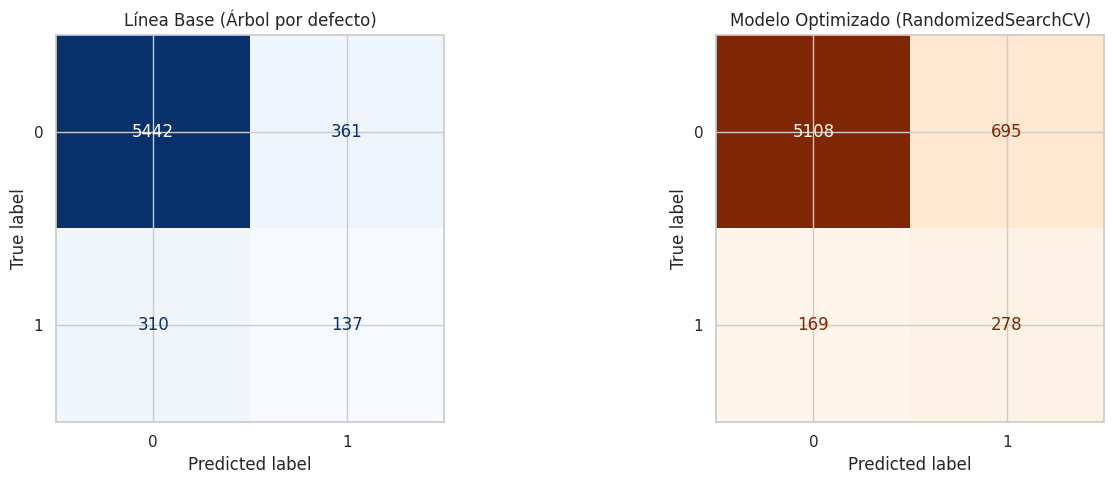

In [ ]:

COSTO_FN = 1_500_000
COSTO_FP = 200_000

def calcular_impacto_financiero(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    vn, fp, fn, vp = cm.ravel()

    perdida_fn = fn * COSTO_FN
    perdida_fp = fp * COSTO_FP
    costo_total = perdida_fn + perdida_fp

    return fp, fn, perdida_fp, perdida_fn, costo_total

# Cálculos para Línea Base
fp_b, fn_b, perd_fp_b, perd_fn_b, costo_b = calcular_impacto_financiero(y_test, y_pred_base)
# Cálculos para Modelo Optimizado
fp_o, fn_o, perd_fp_o, perd_fn_o, costo_o = calcular_impacto_financiero(y_test, y_pred_opt)

print("======================================================")
print("   IMPACTO FINANCIERO EN EL CONJUNTO DE PRUEBA       ")
print("======================================================")
print(f"LÍNEA BASE:")
print(f" - Falsos Positivos: {fp_b} -> Pérdida por oportunidad: ${perd_fp_b:,.0f}")
print(f" - Falsos Negativos: {fn_b} -> Pérdida por impago:      ${perd_fn_b:,.0f}")
print(f" - COSTO TOTAL ESTIMADO: ${costo_b:,.0f}\n")

print(f"MODELO OPTIMIZADO:")
print(f" - Falsos Positivos: {fp_o} -> Pérdida por oportunidad: ${perd_fp_o:,.0f}")
print(f" - Falsos Negativos: {fn_o} -> Pérdida por impago:      ${perd_fn_o:,.0f}")
print(f" - COSTO TOTAL ESTIMADO: ${costo_o:,.0f}")
print("======================================================")

# Visualización de las Matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_base, cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title("Línea Base (Árbol por defecto)")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_opt, cmap='Oranges', ax=axes[1], colorbar=False)
axes[1].set_title("Modelo Optimizado (RandomizedSearchCV)")

plt.tight_layout()
plt.show()

In [ ]:
# Tabla resumen comparativa: cuadrantes de la matriz y costos (base para el análisis 4.2)
vn_b, _, _, vp_b = confusion_matrix(y_test, y_pred_base).ravel()
vn_o, _, _, vp_o = confusion_matrix(y_test, y_pred_opt).ravel()

resumen = pd.DataFrame({
    'Línea Base': [vn_b, fp_b, fn_b, vp_b, perd_fn_b, perd_fp_b, costo_b],
    'Modelo Optimizado': [vn_o, fp_o, fn_o, vp_o, perd_fn_o, perd_fp_o, costo_o],
}, index=['VN (pagan y se aprueban)', 'FP (pagan y se rechazan)', 'FN (impago y se aprueban)',
          'VP (impago y se rechazan)', 'Pérdida por FN ($)', 'Pérdida por FP ($)', 'Costo total ($)'])
display(resumen.style.format('{:,.0f}'))

total_impagos = int((y_test == 1).sum())
costo_aprobar_todos = total_impagos * COSTO_FN
print(f"\nAhorro del optimizado vs. línea base: ${costo_b - costo_o:,.0f} ({(costo_b - costo_o) / costo_b:.1%})")
print(f"Costo de aprobar a todos (referencia): ${costo_aprobar_todos:,.0f}")
print(f"Reducción vs. aprobar a todos -> base: {(costo_aprobar_todos - costo_b) / costo_aprobar_todos:.1%} | optimizado: {(costo_aprobar_todos - costo_o) / costo_aprobar_todos:.1%}")

,Línea Base,Modelo Optimizado
VN (pagan y se aprueban),"5,442","5,108"
FP (pagan y se rechazan),361,695
FN (impago y se aprueban),310,169
VP (impago y se rechazan),137,278
Pérdida por FN ($),"465,000,000","253,500,000"
Pérdida por FP ($),"72,200,000","139,000,000"
Costo total ($),"537,200,000","392,500,000"



Ahorro del optimizado vs. línea base: $144,700,000 (26.9%)
Costo de aprobar a todos (referencia): $670,500,000
Reducción vs. aprobar a todos -> base: 19.9% | optimizado: 41.5%


### Lectura de la matriz del modelo optimizado

Sobre las 6.250 solicitudes del conjunto de prueba:
1. 5.108 clientes pagaron y el modelo aprobó su crédito (Verdaderos Negativos).
2. 695 clientes pagaron pero el modelo les negó el crédito (Falsos Positivos).
3. 169 clientes no pagaron pero el modelo les otorgó el crédito (Falsos Negativos).
4. 278 clientes no pagaron y el modelo les negó el crédito (Verdaderos Positivos).

El modelo optimizado comete más errores en total que la línea base (864 vs 671), pero la mayoría son Falsos Positivos, que cuestan 7,5 veces menos que un Falso Negativo. Con los costos estimados del enunciado, esto se traduce en un menor costo total en el conjunto de prueba (\$392,5 millones vs \$537,2 millones). La interpretación detallada y sus limitaciones están en la sección siguiente.

### Análisis 4.2: Interpretación de la matriz de confusión e impacto financiero

El conjunto de prueba tiene 6.250 solicitudes, de las cuales 447 (7,15 %) terminan en impago. Cada error del modelo tiene un costo distinto: un **Falso Negativo (FN)** es un crédito otorgado que no se paga (pérdida directa de \$1.500.000) y un **Falso Positivo (FP)** es un buen cliente rechazado (pérdida de intereses de \$200.000). Un FN cuesta 7,5 veces más que un FP.

| | Línea Base | Modelo Optimizado |
|---|---|---|
| Verdaderos Negativos (pagan y se aprueban) | 5.442 | 5.108 |
| Falsos Positivos (pagan y se rechazan) | 361 | 695 |
| Falsos Negativos (impago y se aprueban) | 310 | 169 |
| Verdaderos Positivos (impago y se rechazan) | 137 | 278 |
| Pérdida por FN | \$465.000.000 | \$253.500.000 |
| Pérdida por FP | \$72.200.000 | \$139.000.000 |
| **Costo total** | **\$537.200.000** | **\$392.500.000** |

**Línea base.** El árbol sin restricciones solo detecta 137 de los 447 impagos (30,65 %) y deja pasar 310. Esos 310 créditos aprobados representan \$465 millones, el 87 % del costo total del modelo. Parece conservador porque rechaza a pocos clientes buenos (361), pero esa aparente prudencia se paga con pérdida de capital. Esto confirma el sobreajuste anticipado en 3.2: pasó de 100 % de accuracy en entrenamiento a 89,3 % en prueba (5.579 de 6.250) y a detectar solo el 30,65 % de los impagos.

**Modelo optimizado.** Detecta 278 de los 447 impagos (62,19 %) y reduce los FN de 310 a 169. Esto evita \$211,5 millones en pérdidas por impago. A cambio, rechaza a 334 clientes buenos adicionales (FP sube de 361 a 695), lo que cuesta \$66,8 millones en intereses no percibidos. El balance neto es un **ahorro de \$144.700.000** (una reducción del 26,9 % del costo total). Como cada FN evitado equivale a 7,5 FP, con los costos estimados del enunciado el cambio resulta conveniente aunque el modelo "se equivoque" más veces en total.

**Referencia.** Aprobar a todos los clientes costaría 447 × \$1.500.000 = \$670.500.000. La línea base reduce ese costo en solo un 19,9 %, mientras que el modelo optimizado lo reduce en un 41,5 %.

**Limitación.** La precisión sigue siendo baja (~28 %): de cada 100 clientes rechazados, solo unos 28 habrían caído en impago. El banco debe aceptar que, para proteger su capital, rechazará a muchos clientes que sí habrían pagado, y puede mitigarlo derivando los casos marginales a revisión manual. Estas cifras se calculan sobre un único conjunto de prueba (6.250 solicitudes) y con costos estimados en estudios preliminares; con otra división de los datos o costos distintos podrían variar.